# Food Analysis AI: Dual-Head Multi-Task & OOD Detection Pipeline
## 1. Setup, Environment & Imports


In [1]:
import gc
import json
import os
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


## 2. Environment Paths & Drive Mounting


In [2]:
try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists():
        drive.mount('/content/drive')
except ImportError:
    pass

BASE_DIR = Path('/content/drive/MyDrive/Food_Analysis_AI')
MODELS_DIR = BASE_DIR / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

SPLITS_DIR = Path('/content/drive/MyDrive/Food_Analysis_Dataset_Splits')
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

def find_file(pattern, search_roots):
    for root in search_roots:
        root_path = Path(root)
        if root_path.exists():
            matches = list(root_path.rglob(pattern))
            if matches:
                return matches[0]
    return None

model_candidate = find_file('EfficientNetB0_finetuned.keras', [MODELS_DIR, BASE_DIR, '/content/drive/MyDrive', '/content'])
PRETRAINED_MODEL_PATH = model_candidate if model_candidate else MODELS_DIR / 'EfficientNetB0_finetuned.keras'

print('Pretrained model target:', PRETRAINED_MODEL_PATH)


Mounted at /content/drive
Pretrained model target: /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_finetuned.keras


## 3. Automated Dataset Loading & Split Restoration


In [3]:
train_csv = SPLITS_DIR / 'train_data.csv'
val_csv = SPLITS_DIR / 'val_data.csv'
test_csv = SPLITS_DIR / 'test_data.csv'

need_rebuild = True
if train_csv.is_file() and val_csv.is_file() and test_csv.is_file():
    train_data = pd.read_csv(train_csv)
    val_data = pd.read_csv(val_csv)
    test_data = pd.read_csv(test_csv)
    if train_data['food_type'].nunique() >= 10:
        need_rebuild = False
        print('Loaded complete 10-class dataset splits from Google Drive.')
    else:
        print('Existing splits only have', train_data['food_type'].nunique(), 'classes. Rebuilding all 10 classes...')

if need_rebuild:
    dataset_dir = Path('/content/Dataset')
    dataset_path = None

    possible_dirs = [
        dataset_dir / 'Fruits_Vegetables_Dataset(12000)',
        Path('/content/Fruits_Vegetables_Dataset(12000)'),
        Path('/content/drive/MyDrive/Fruits_Vegetables_Dataset(12000)')
    ]
    for d in possible_dirs:
        if d.is_dir() and any(d.iterdir()):
            dataset_path = d
            break

    if dataset_path is None:
        zip_candidates = [
            Path('/content/drive/MyDrive/Fruits_Vegetables_Dataset(12000).zip'),
            Path('/content/Fruits_Vegetables_Dataset(12000).zip')
        ]
        found_zip = None
        for z in zip_candidates:
            if z.is_file():
                found_zip = z
                break
        if found_zip is None:
            found_zip = find_file('*Fruits*12000*.zip', ['/content/drive/MyDrive', '/content'])

        if found_zip and found_zip.is_file():
            print(f'Extracting dataset from: {found_zip}')
            dataset_dir.mkdir(parents=True, exist_ok=True)
            with zipfile.ZipFile(found_zip, 'r') as zf:
                zf.extractall(dataset_dir)
            extracted_sub = list(dataset_dir.glob('**/FreshApple'))
            if extracted_sub:
                parent = extracted_sub[0].parent
                dataset_path = parent.parent if parent.name in ('Fruits', 'Vegetables') else parent
            else:
                dataset_path = dataset_dir
        else:
            raise FileNotFoundError('Could not locate dataset folder or ZIP archive in Google Drive.')

    print(f'Using dataset path: {dataset_path}')
    records = []
    valid_exts = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}
    for p in dataset_path.rglob('*'):
        if p.is_file() and p.suffix.lower() in valid_exts:
            folder_name = p.parent.name
            cond = 'Fresh' if folder_name.startswith('Fresh') else ('Rotten' if folder_name.startswith('Rotten') else None)
            if cond:
                ftype = folder_name[len(cond):].strip()
                records.append({
                    'path': str(p.resolve()),
                    'condition': cond,
                    'food_type': ftype,
                    'target': 1 if cond == 'Rotten' else 0
                })

    df_all = pd.DataFrame(records)
    combined = df_all['condition'] + '|' + df_all['food_type']
    train_data, held_out = train_test_split(df_all, test_size=0.20, random_state=RANDOM_STATE, stratify=combined)
    held_comb = held_out['condition'] + '|' + held_out['food_type']
    val_data, test_data = train_test_split(held_out, test_size=0.50, random_state=RANDOM_STATE, stratify=held_comb)

    train_data = train_data.reset_index(drop=True)
    val_data = val_data.reset_index(drop=True)
    test_data = test_data.reset_index(drop=True)

    train_data.to_csv(train_csv, index=False)
    val_data.to_csv(val_csv, index=False)
    test_data.to_csv(test_csv, index=False)
    print(f'Splits created and cached in: {SPLITS_DIR}')

FOOD_CLASSES = sorted(train_data['food_type'].dropna().unique().tolist())
FOOD_TO_ID = {name: idx for idx, name in enumerate(FOOD_CLASSES)}
ID_TO_FOOD = {idx: name for idx, name in enumerate(FOOD_CLASSES)}
CONDITION_CLASSES = ['Fresh', 'Rotten']

train_data['food_label'] = train_data['food_type'].map(FOOD_TO_ID)
val_data['food_label'] = val_data['food_type'].map(FOOD_TO_ID)
test_data['food_label'] = test_data['food_type'].map(FOOD_TO_ID)

print('Food Classes:', FOOD_CLASSES)
print(f'Total classes: {len(FOOD_CLASSES)} | Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}')


Extracting dataset from: /content/drive/MyDrive/Fruits_Vegetables_Dataset(12000).zip
Using dataset path: /content/Dataset/Fruits_Vegetables_Dataset(12000)
Splits created and cached in: /content/drive/MyDrive/Food_Analysis_Dataset_Splits
Food Classes: ['Apple', 'Banana', 'Bellpepper', 'Carrot', 'Cucumber', 'Mango', 'Orange', 'Potato', 'Strawberry', 'Tomato']
Total classes: 10 | Train: 9600, Val: 1200, Test: 1200


## 4. Multi-Task Data Generator


In [4]:
class DualHeadDataGenerator(keras.utils.Sequence):
    def __init__(self, df, batch_size=BATCH_SIZE, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_rows = self.df.iloc[batch_idx]

        images = []
        for path_str in batch_rows['path']:
            with Image.open(path_str) as img:
                img = img.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
                images.append(np.asarray(img, dtype=np.float32) / 255.0)

        x = np.array(images, dtype=np.float32)
        y_food = batch_rows['food_label'].values.astype(np.int32)
        y_cond = batch_rows['target'].values.astype(np.float32)

        return x, {'food_type': y_food, 'condition': y_cond}

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

train_loader = DualHeadDataGenerator(train_data, BATCH_SIZE, shuffle=True)
val_loader = DualHeadDataGenerator(val_data, BATCH_SIZE, shuffle=False)
test_loader = DualHeadDataGenerator(test_data, BATCH_SIZE, shuffle=False)


## 5. Load Pretrained Model & Construct Dual-Head Architecture


In [5]:
if not PRETRAINED_MODEL_PATH.is_file():
    raise FileNotFoundError(f'Pretrained model not found at {PRETRAINED_MODEL_PATH}. Check Google Drive path.')

loaded_model = keras.models.load_model(PRETRAINED_MODEL_PATH, compile=False)

inputs = loaded_model.input

feature_layer = None
for layer in loaded_model.layers:
    if 'head_dense' in layer.name or 'global_average_pooling' in layer.name:
        feature_layer = layer
        break

if feature_layer is None:
    for layer in loaded_model.layers:
        if isinstance(layer, keras.Model) and 'efficientnet' in layer.name.lower():
            backbone = layer
            x = backbone(inputs)
            feature_layer = layers.GlobalAveragePooling2D(name='shared_gap')(x)
            break

condition_output = loaded_model.output

shared_features = feature_layer.output if hasattr(feature_layer, 'output') else feature_layer
food_branch = layers.Dense(128, activation='relu', name='food_head_dense')(shared_features)
food_branch = layers.Dropout(0.2, name='food_head_dropout')(food_branch)
food_output = layers.Dense(len(FOOD_CLASSES), activation='softmax', name='food_type')(food_branch)

dual_model = keras.Model(
    inputs=inputs,
    outputs={'food_type': food_output, 'condition': condition_output},
    name='EfficientNetB0_DualHead'
)

for layer in dual_model.layers:
    if layer.name not in ['food_head_dense', 'food_head_dropout', 'food_type']:
        layer.trainable = False

dual_model.summary()


Model: "EfficientNetB0_DualHead"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ normalized_rgb      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ training_augmentat… │ (None, 224, 224,  │          0 │ normalized_rgb[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ restore_pixel_range │ (None, 224, 224,  │          0 │ training_augment… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ restore_pixel_ra… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout_1      │ (None, 1280)      │          0 │ global_avg_pool[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dense (Dense)  │ (None, 128)       │    163,968 │ head_dropout_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ food_head_dense     │ (None, 128)       │     16,512 │ head_dense[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout_2      │ (None, 128)       │          0 │ head_dense[0][0]  │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ food_head_dropout   │ (None, 128)       │          0 │ food_head_dense[… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rotten_probability  │ (None, 1)         │        129 │ head_dropout_2[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ food_type (Dense)   │ (None, 10)        │      1,290 │ food_head_dropou… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,231,470 (16.14 MB)

 Trainable params: 17,802 (69.54 KB)

 Non-trainable params: 4,213,668 (16.07 MB)

In [6]:
import zipfile
from pathlib import Path

zip_path = Path('/content/drive/MyDrive/Fruits_Vegetables_Dataset(12000).zip')
extract_dir = Path('/content/Dataset')
dataset_dir = extract_dir / 'Fruits_Vegetables_Dataset(12000)'

if not dataset_dir.is_dir():
    extract_dir.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zf:
        zf.extractall(extract_dir)
    print('Dataset extracted successfully to /content/Dataset!')
else:
    print('Dataset already extracted.')

Dataset already extracted.


## 6. Model Compilation & Training of the Food Type Head


In [7]:
dual_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss={
        'food_type': keras.losses.SparseCategoricalCrossentropy(),
        'condition': keras.losses.BinaryCrossentropy()
    },
    loss_weights={
        'food_type': 1.0,
        'condition': 0.0
    },
    metrics={
        'food_type': ['accuracy'],
        'condition': ['accuracy']
    }
)

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_food_type_accuracy', mode='max', patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_food_type_loss', mode='min', factor=0.5, patience=2, min_lr=1e-5)
]

history = dual_model.fit(
    train_loader,
    validation_data=val_loader,
    epochs=6,
    callbacks=callbacks
)

Epoch 1/6
 72/300 ━━━━━━━━━━━━━━━━━━━━ 52s 229ms/step - condition_accuracy: 0.9850 - condition_loss: 0.0435 - food_type_accuracy: 0.3250 - food_type_loss: 2.0020 - loss: 2.0020

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


300/300 ━━━━━━━━━━━━━━━━━━━━ 120s 337ms/step - condition_accuracy: 0.9837 - condition_loss: 0.0459 - food_type_accuracy: 0.7136 - food_type_loss: 0.9101 - loss: 0.9101 - val_condition_accuracy: 0.9883 - val_condition_loss: 0.0309 - val_food_type_accuracy: 0.9033 - val_food_type_loss: 0.3724 - val_loss: 0.3724 - learning_rate: 0.0010
Epoch 2/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 86s 286ms/step - condition_accuracy: 0.9835 - condition_loss: 0.0460 - food_type_accuracy: 0.8478 - food_type_loss: 0.4694 - loss: 0.4694 - val_condition_accuracy: 0.9883 - val_condition_loss: 0.0309 - val_food_type_accuracy: 0.9242 - val_food_type_loss: 0.2754 - val_loss: 0.2761 - learning_rate: 0.0010
Epoch 3/6
300/300 ━━━━━━━━━━━━━━━━━━━━ 87s 289ms/step - condition_accuracy: 0.9831 - condition_loss: 0.0470 - food_type_accuracy: 0.8748 - food_type_loss: 0.3907 - loss: 0.3907 - val_condition_accuracy: 0.9883 - val_condition_loss: 0.0309 - val_food_type_accuracy: 0.9200 - val_food_type_loss: 0.2542 - val_loss: 0.2543 -

## 7. Learning Curves Visualization


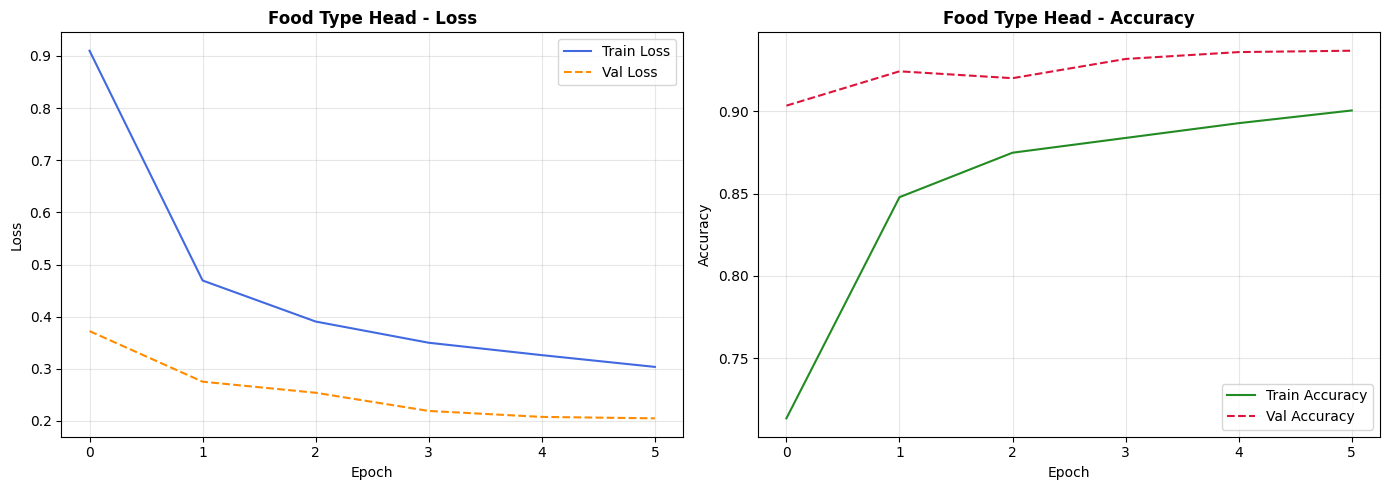

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['food_type_loss'], label='Train Loss', color='royalblue')
axes[0].plot(history.history['val_food_type_loss'], label='Val Loss', color='darkorange', linestyle='--')
axes[0].set_title('Food Type Head - Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['food_type_accuracy'], label='Train Accuracy', color='forestgreen')
axes[1].plot(history.history['val_food_type_accuracy'], label='Val Accuracy', color='crimson', linestyle='--')
axes[1].set_title('Food Type Head - Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8. Test Set Evaluation & Classification Reports


In [9]:
predictions = dual_model.predict(test_loader, verbose=1)
pred_food_probs = predictions['food_type']
pred_food_ids = np.argmax(pred_food_probs, axis=-1)
pred_cond_probs = predictions['condition'].reshape(-1)
pred_cond_ids = (pred_cond_probs >= 0.30).astype(int)

y_true_food = test_data['food_label'].values
y_true_cond = test_data['target'].values

print('=== Food Type Classification Report ===')
print(classification_report(y_true_food, pred_food_ids, target_names=FOOD_CLASSES, digits=4))

print('=== Condition Classification Report (Validation of Preservation) ===')
print(classification_report(y_true_cond, pred_cond_ids, target_names=CONDITION_CLASSES, digits=4))


38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 299ms/step
=== Food Type Classification Report ===
              precision    recall  f1-score   support

       Apple     0.7838    0.9667    0.8657       120
      Banana     0.9748    0.9748    0.9748       119
  Bellpepper     0.8880    0.9250    0.9061       120
      Carrot     0.9487    0.9250    0.9367       120
    Cucumber     0.9825    0.9256    0.9532       121
       Mango     0.9818    0.9000    0.9391       120
      Orange     0.9421    0.9500    0.9461       120
      Potato     0.8898    0.8750    0.8824       120
  Strawberry     0.9600    1.0000    0.9796       120
      Tomato     0.9709    0.8333    0.8969       120

    accuracy                         0.9275      1200
   macro avg     0.9322    0.9275    0.9280      1200
weighted avg     0.9322    0.9275    0.9280      1200

=== Condition Classification Report (Validation of Preservation) ===
              precision    recall  f1-score   support

       Fresh     0.9885    0.9885  

## 9. Food Type Confusion Matrix


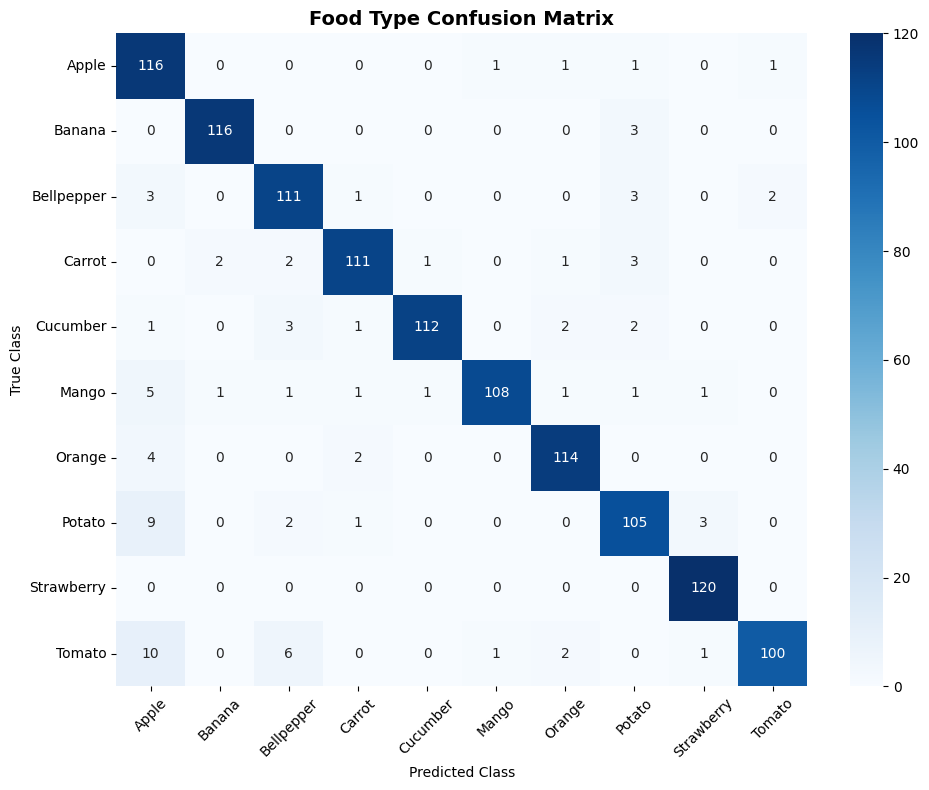

In [10]:
cm = confusion_matrix(y_true_food, pred_food_ids)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=FOOD_CLASSES, yticklabels=FOOD_CLASSES)
plt.title('Food Type Confusion Matrix', fontweight='bold', fontsize=14)
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 10. Out-of-Distribution (OOD) Calibration & Confidence Thresholding


Percentile 1% of In-Distribution Confidence: 0.3714
Percentile 5% of In-Distribution Confidence: 0.5123
Percentile 10% of In-Distribution Confidence: 0.6521
Percentile 50% of In-Distribution Confidence: 0.9879


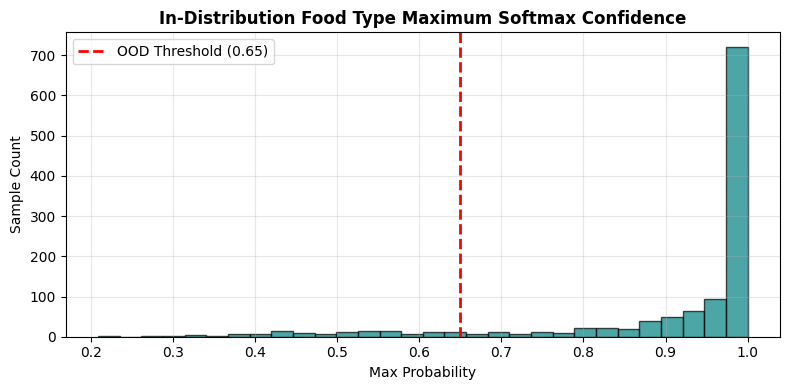

In [11]:
max_food_confidences = np.max(pred_food_probs, axis=-1)

percentiles = [1, 5, 10, 50]
threshold_values = np.percentile(max_food_confidences, percentiles)

for p, val in zip(percentiles, threshold_values):
    print(f'Percentile {p}% of In-Distribution Confidence: {val:.4f}')

OOD_FOOD_THRESHOLD = 0.65
UNCERTAIN_LOW = 0.35
UNCERTAIN_HIGH = 0.65

plt.figure(figsize=(8, 4))
plt.hist(max_food_confidences, bins=30, color='teal', edgecolor='black', alpha=0.7)
plt.axvline(OOD_FOOD_THRESHOLD, color='red', linestyle='--', linewidth=2, label=f'OOD Threshold ({OOD_FOOD_THRESHOLD})')
plt.title('In-Distribution Food Type Maximum Softmax Confidence', fontweight='bold')
plt.xlabel('Max Probability')
plt.ylabel('Sample Count')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 11. End-to-End Decision & Test Case Simulator


In [12]:
def evaluate_test_image(image_path, declared_item=None):
    with Image.open(image_path) as img:
        img_rgb = img.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
        batch = np.asarray(img_rgb, dtype=np.float32)[np.newaxis, ...] / 255.0

    preds = dual_model(batch, training=False)
    food_probs = preds['food_type'].numpy()[0]
    cond_prob = float(preds['condition'].numpy()[0, 0])

    top_food_idx = int(np.argmax(food_probs))
    top_food_name = ID_TO_FOOD[top_food_idx]
    top_food_conf = float(food_probs[top_food_idx])

    if top_food_conf < OOD_FOOD_THRESHOLD:
        return {
            'test_code': 'TC-04 / TC-05',
            'status': 'REJECTED_OOD',
            'message': 'Item not recognized as a supported fresh fruit or vegetable. Please capture food clearly.',
            'detected_item': None,
            'confidence': round(top_food_conf, 4),
            'routing': 'MANUAL_HEALTH_OFFICER_REVIEW',
            'is_final_decision': False
        }

    if declared_item and declared_item.strip().lower() != top_food_name.lower():
        return {
            'test_code': 'TC-07',
            'status': 'MISMATCH',
            'message': 'Food item in image does not match the declared order item.',
            'declared_item': declared_item,
            'detected_item': top_food_name,
            'confidence': round(top_food_conf, 4),
            'routing': 'ALERT_INSPECTOR_AND_OFFICER',
            'is_final_decision': False
        }

    if UNCERTAIN_LOW <= cond_prob <= UNCERTAIN_HIGH:
        cond_label = 'Fresh' if cond_prob < 0.50 else 'Rotten'
        cond_score = round(max(cond_prob, 1.0 - cond_prob) * 100)
        return {
            'test_code': 'TC-18',
            'status': 'UNCERTAIN',
            'message': f'Inconclusive result - {cond_label} {cond_score}%. Retake requested from another angle.',
            'detected_item': top_food_name,
            'routing': 'REQUIRES_DETAILED_EXAMINATION',
            'decision_status': 'PENDING_HEALTH_OFFICER_REVIEW',
            'is_final_decision': False
        }

    is_rotten = cond_prob >= 0.30
    final_cond = 'Rotten' if is_rotten else 'Fresh'
    final_conf = cond_prob if is_rotten else 1.0 - cond_prob

    return {
        'test_code': 'TC-21',
        'status': 'ANALYZED',
        'detected_item': top_food_name,
        'item_confidence': round(top_food_conf, 4),
        'condition': final_cond,
        'condition_confidence': round(final_conf, 4),
        'decision_status': 'PENDING_HEALTH_OFFICER_REVIEW',
        'is_final_decision': False
    }

sample_row = test_data.iloc[0]
print('Simulation Test Result:')
print(json.dumps(evaluate_test_image(sample_row['path'], declared_item=sample_row['food_type']), indent=2))

Simulation Test Result:
{
  "test_code": "TC-21",
  "status": "ANALYZED",
  "detected_item": "Banana",
  "item_confidence": 0.9932,
  "condition": "Rotten",
  "condition_confidence": 0.9999,
  "decision_status": "PENDING_HEALTH_OFFICER_REVIEW",
  "is_final_decision": false
}


## 12. Save Dual-Head Keras Model & Deployment Configuration


In [13]:
DUAL_MODEL_KERAS_PATH = MODELS_DIR / 'EfficientNetB0_dualhead.keras'
dual_model.save(DUAL_MODEL_KERAS_PATH)

dual_config = {
    'model_file': 'food_model_dual.tflite',
    'model_name': 'EfficientNetB0_dualhead',
    'image_size': list(IMAGE_SIZE),
    'condition_threshold': 0.30,
    'ood_food_threshold': OOD_FOOD_THRESHOLD,
    'uncertainty_range': [UNCERTAIN_LOW, UNCERTAIN_HIGH],
    'food_classes': FOOD_CLASSES,
    'food_to_id': FOOD_TO_ID,
    'condition_classes': CONDITION_CLASSES,
    'preprocessing': {
        'color_mode': 'RGB',
        'rescale': '1/255.0',
        'interpolation': 'bilinear'
    }
}

CONFIG_SAVE_PATH = MODELS_DIR / 'final_config_dual.json'
with open(CONFIG_SAVE_PATH, 'w', encoding='utf-8') as f:
    json.dump(dual_config, f, indent=2, ensure_ascii=False)

print('Saved Keras model to:', DUAL_MODEL_KERAS_PATH)
print('Saved Config to:', CONFIG_SAVE_PATH)


Saved Keras model to: /content/drive/MyDrive/Food_Analysis_AI/models/EfficientNetB0_dualhead.keras
Saved Config to: /content/drive/MyDrive/Food_Analysis_AI/models/final_config_dual.json


## 13. Convert Dual-Head Model to TFLite for Fast Deployment


In [14]:
height, width = IMAGE_SIZE

@tf.function(input_signature=[tf.TensorSpec([1, height, width, 3], tf.float32, name='normalized_rgb')])
def serve_dual(x):
    outputs = dual_model(x, training=False)
    return {
        'food_type': outputs['food_type'],
        'rotten_probability': outputs['condition']
    }

converter = tf.lite.TFLiteConverter.from_concrete_functions(
    [serve_dual.get_concrete_function()],
    dual_model
)
converter.optimizations = []
tflite_model_bytes = converter.convert()

TFLITE_SAVE_PATH = MODELS_DIR / 'food_model_dual.tflite'
TFLITE_SAVE_PATH.write_bytes(tflite_model_bytes)

print(f'Successfully exported TFLite model to: {TFLITE_SAVE_PATH}')
print(f'TFLite size: {len(tflite_model_bytes) / (1024 * 1024):.2f} MB')


Successfully exported TFLite model to: /content/drive/MyDrive/Food_Analysis_AI/models/food_model_dual.tflite
TFLite size: 16.00 MB
